# OutcropHyBNet reproduction on COCO-Stuff 10K: final run (3 models, full power)

**Paper:** H. Madokoro, K. Sato, S. Nix, S. Chiyonobu, T. Nagayoshi, K. Sato. *OutcropHyBNet: Hybrid Backbone Networks with Data Augmentation for Accurate Stratum Semantic Segmentation of Monocular Outcrop Images in Carbon Capture and Storage Applications.* Sensors 23(21):8809, 2023. https://doi.org/10.3390/s23218809 (open access, CC BY).

## What this notebook is

The first two studies (18 models at 4,000 iterations, then 8 models at 8,000 iterations) picked the winners. This notebook trains **one final model per contender** with more training, a larger image size and all the training data:

| Model | Family | Why it is here | Focused-study score (8,000 iters, 384 px) |
|---|---|---|---|
| SegFormer MiT-B1 | transformer | best model overall | 33.37 mIoU |
| DeepLabV3+ ResNet-101 (AdamW) | CNN | best DeepLab-family model | 31.16 mIoU |
| DeepLabV3 MobileNetV3 | light CNN | best DeepLab with a MobileNetV3 backbone | 25.78 mIoU |

## What changed compared with the focused study ("more power")

| Setting | Focused study | Final run | Why |
|---|---|---|---|
| Image size | 384 px | **512 px** (all three models) | the paper's DeepLab size; the earlier runs used only 4.5 to 6 GB of memory, so there is room |
| Training length | 8,000 iterations | **16,000 iterations** (about 14 passes over the data) | DeepLab was still improving fastest with more training |
| Training images | 8,100 | **9,000** (all of them) | no validation set needed (see below) |
| ResNet-101 | no auxiliary head | **auxiliary head on** (the paper's DeepLab setup) | cheap extra training signal; adds almost no memory |
| Batch size, optimisers, learning rates | batch 8; AdamW for SegFormer and ResNet-101, SGD for MobileNetV3 DeepLabV3 | unchanged | keeps the comparison with earlier rounds clean |

## Why there is no validation set

In the earlier studies the validation images were used for three things: watching progress during training, choosing per-class weights for late-fusion hybrids, and a validation score column. The final run needs none of them: the schedule is fixed, the last checkpoint is the one that is scored, nothing is tuned, and there are no hybrids. So all 9,000 official training images are used for training and the 1,000 official test images are used only for the final score. This is also the standard COCO-Stuff10K protocol. One honest caveat: the choice of *which* models to carry forward was informed by test scores from the earlier rounds, which can make the final numbers slightly optimistic (nothing was tuned on the test set during these runs).

## Read this first

1. **Smoke test first (recommended, a few minutes):** set `PRESET = "smoke"` in cell 5, run the notebook down to the three run cells, then switch back to `"final"` and restart the runtime. This checks the auxiliary-head path and the checkpoint saving, neither of which has been run in this notebook before. To test resuming, stop the first smoke run after a few seconds (checkpoints are written every 10 iterations there) and run the cell again.
2. **Memory (estimates from the earlier measurements, 15 GB T4):** about 7 to 8 GB for MiT-B1, 10 to 11 GB for ResNet-101 and 6 to 7 GB for MobileNetV3 at 512 px and batch 8. If a run runs out of memory it is retried automatically with half the batch size and twice the iterations.
3. **Time (rough extrapolation):** the earlier runs took 37 to 44 minutes per 8,000 iterations at 384 px, so expect roughly 2 to 3 hours per model here, 7 to 8 hours in total. Each finished run is saved to Google Drive, and a run in progress writes a resume checkpoint every 1,000 iterations (roughly every 8 to 10 minutes), so a disconnect loses at most that much work: just re-run the same cell and it continues ("resuming ... from iteration N" is printed). To save about a quarter of the time, lower `iters` to 12000 in the `final` preset.
4. **Single seed:** differences of 1 to 2 points can be noise. Set `SEEDS = [0, 1, 2]` for error bars (this triples the cost).
5. **MobileNetV3 recipe:** DeepLabV3 MobileNetV3 uses SGD because that is the configuration that scored 25.78. Set `MN3_OPTIM = "adamw"` in the groups cell (Section 7) to use AdamW instead; this was not tested for that model.
6. **The paper's "hybrid" is a framework, not a single fused network**, and no hybrid is trained here (none beat SegFormer alone in earlier rounds).

## Run order

| Section | What it does |
|---|---|
| 1. Paper methodology | Specification extracted from the paper, and what it leaves unstated |
| 2. Setup | Imports, presets (the `final` preset is the default), constants |
| 3. Data | Download/convert COCO-Stuff10K, label mapping, splits (9,000 train / 0 val / 1,000 test) |
| 4. Augmentation | `none` / `standard` (MMSeg-style) / `strong`; the final run uses `standard` |
| 5. Models | DeepLabV3, DeepLabV3+, SegFormer, fused hybrid (not used here), late fusion (not used here) |
| 6. Train / evaluate / profile | Metrics, speed, memory |
| 7. Experiments | The three final runs |
| 8. Results | Leaderboard against the focused study, charts, paper comparison, deviations, auto-report |


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Methodology extracted from the paper

All section/table numbers refer to Madokoro et al. 2023.

### 1.1 Method overview (Sec. 3)

* **OutcropHyBNet** = a baseline that integrates **DeepLabv3+** (CNN) and **SegFormer** (transformer) as backbones, plus **OASIS** GAN image synthesis to enlarge the training set. DeepLabv3+ is argued to be stronger on texture/"stuff" classes, SegFormer elsewhere, so the framework "flexibly" uses either backbone depending on the target.
* **Loss:** pixel-wise cross-entropy (Eq. 3).
* **Class balancing (Sec. 4.3, Eq. 6):** `z = x/y` (class pixel share), `w = median(z)/z`. Used for the outcrop data (Table 1 weights: Black 1.0, Red 1.2570, Cyan 0.7384, Yellow 0.3792).
* **Metrics (Sec. 3.4):** IoU per class (Eq. 5) and mIoU; FID (Eq. 4) for synthetic image quality; confusion matrices; per-class win counts between models.

### 1.2 Architectures and backbones

| Model | Backbone (Table 6) | Crop | LR | Weight decay | Description in paper |
|---|---|---|---|---|---|
| **DeepLabv3+** | ResNet-101 | 512x512 | 1.0e-2 | 5.0e-4 | Encoder-decoder, atrous convolutions, ASPP, bilinear-upsampling decoder with skip connection from earlier layers |
| **SegFormer** | MiT-B5 | 640x640 | 6.0e-5 | 1.0e-2 | Hierarchical Mix-Transformer encoder (overlapped patch merging, efficient self-attention, Mix-FFN with 3x3 conv), all-MLP decoder |
| OCRNet | HRNetV2p-W48 | 512x512 | 1.0e-2 | 5.0e-4 | outcrop backbone study only |
| U-Net | U-Net | 512x1024 | 1.0e-2 | 5.0e-4 | outcrop backbone study only |
| K-Net | Swin-L | 640x640 | 6.0e-5 | 5.0e-4 | outcrop backbone study only |
| SETR | ViT-L | 512x512 | 1.0e-3 | 0.0 | outcrop backbone study only |
| Twins | SVT-L | 512x512 | 6.0e-5 | 1.0e-2 | outcrop backbone study only |

* **OASIS (Table 3):** 37,399 iterations (200 epochs), generator LR 1e-4, discriminator LR 4e-4, batch 16, 256x256 input, 2,995 train / 333 test label maps. The discriminator is a U-Net-style segmenter with N+1 classes and per-batch inverse-frequency class weights.

### 1.3 Pretrained backbones

The paper only says DeepLabv3+ encoders are "usually pretrained CNNs such as ResNet or Xception" and that **hyper-parameters were taken from the MMSegmentation config of the model that scored best on ADE20K**. It does not name the checkpoints. It is **ambiguous (AMB-1)** whether weights were initialised from ImageNet or from MMSeg's ADE20K-trained checkpoints. This notebook uses **ImageNet-1k pretrained encoders** (timm `resnet18`, `resnet101`, `mobilenetv3_large_100`; Hugging Face `nvidia/mit-b*`).

### 1.4 Training and evaluation settings

| Item | Paper | Source |
|---|---|---|
| Framework | MMSegmentation (OpenMMLab), PyTorch | Sec. 4.2 |
| Hardware | 1x NVIDIA RTX A6000, 48 GB | Sec. 4.2 |
| Benchmarks | COCO-Stuff10K (10,000 images, 80 thing + 91 stuff classes), ADE20K | Sec. 4.1 |
| Outcrop backbone study | batch 8, 4 classes, 256x256 input, 50 epochs, 64/128/256/512 samples drawn from 13 images, 9:1 train/test | Sec. 4.5 |
| Augmentation study | 256 sampled images x 13 + 333 OASIS images = 3,661 images; 9:1 split = 3,294 train / 367 test | Sec. 4.4 |
| Metric on benchmarks | per-class IoU, mIoU | Sec. 4.6 |

**Not stated in the paper** (each gap and how it is filled is in the deviation table): optimizer family and momentum (SGD appears only in the abbreviation list), LR schedule and warmup, iteration count and batch size for COCO-Stuff10K, benchmark augmentation pipeline, ImageNet vs ADE20K initialisation, evaluation protocol (single/multi-scale), validation split, mixed precision, seeds, and any speed/memory measurement.

### 1.5 Augmentation procedure

The only augmentation the paper describes is **OASIS image synthesis for the outcrop data** (real + synthetic images in one training set). For COCO-Stuff10K no augmentation is described; because MMSegmentation was used, the standard MMSeg training pipeline (random rescale 0.5-2.0, random crop with `cat_max_ratio=0.75`, horizontal flip, photometric distortion) is the likely default but is an inference, not a statement.

### 1.6 Results reported for COCO-Stuff10K (the reproduction targets)

| Quantity | Paper |
|---|---|
| mIoU DeepLabv3+ | **38.78 %** |
| mIoU SegFormer | **48.40 %** |
| Classes where DeepLabv3+ beats SegFormer | things: surfboard, sports ball, car, mouse (4/80); stuff: platform, mountain, stone, straw, bush, bridge, roof, house, cabinet, floor-other, floor-wood, carpet, wall-panel (13/91) |
| Implied SegFormer wins | 154/171 = 90 % (171 - 17) |
| Qualitative claim | DeepLabv3+ wins a larger share of *stuff* classes than of *thing* classes |
| Top-10 IoU classes (Table 8) | DeepLabv3+: zebra, person, snow, stop sign, horse, surfboard, bus, fire hydrant, airplane, tree. SegFormer: snow, cow, broccoli, parking meter, bear, elephant, cat, train, fire hydrant, zebra |

### 1.7 Inconsistencies noticed in the paper

* **P-1.** Sec. 4.6 first paragraph attaches "138 of 150 classes" to COCO-Stuff10K and "154 of 171" to ADE20K. The class counts are swapped (COCO-Stuff has 171 classes, ADE20K 150), and the appendix lists confirm it: 17 DeepLab wins on COCO-Stuff10K gives 154/171 and 12 on ADE20K gives 138/150. The mIoU values in that paragraph could be affected by the same slip; they are used as written.
* **P-2.** Sec. 4.1 describes ADE20K as 150 object + 50 stuff categories, while the appendix splits it 115 things + 35 stuff = 150.
* **P-3.** The paper reports no inference time or memory figure in the sections I read, so the speed/memory results here have no paper baseline.

## 2. Setup
Pick a preset. `smoke` runs the whole pipeline on tiny subsets with tiny images (use it to validate the code). `default` is a moderate budget. `paper_like` is closer to MMSeg-style schedules. **Iteration counts are my choices; the paper does not state them.**

**This notebook uses the `final` preset** (16,000 iterations, batch size 8, 512 px, all 9,000 training images, no validation set) and stores results in `runs_final/` (inside Google Drive when it is mounted). Older presets are kept so earlier studies can be repeated.


In [2]:
# !pip install -q torch torchvision timm transformers scipy pillow pandas matplotlib tqdm
import os, sys, json, math, time, random, gc, zipfile, urllib.request, warnings
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.v2.functional as TVF
from PIL import Image
from tqdm.auto import tqdm
import timm
from transformers import SegformerForSemanticSegmentation, SegformerModel, SegformerConfig

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| timm", timm.__version__, "| device:", DEVICE,
      torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

torch 2.11.0+cpu | timm 1.0.30 | device: cpu 


In [3]:
PRESET = "final"      # "smoke" | "default" | "paper_like"   <-- change after the smoke test passes

PRESETS = {
    "smoke":      dict(iters=20,    bs=2,  workers=0, warmup=5,    eval_every=0, ckpt_every=10,
                       train_subset=32, val_subset=16, test_subset=16,
                       res_list=(96, 128, 160), bench_warmup=1, bench_iters=3),
    "default":    dict(iters=8000,  bs=8,  workers=4, warmup=800,  eval_every=2000,
                       train_subset=None, val_subset=None, test_subset=None,
                       res_list=(256, 384, 512), bench_warmup=20, bench_iters=100),
    "paper_like": dict(iters=40000, bs=16, workers=8, warmup=1500, eval_every=4000,
                       train_subset=None, val_subset=None, test_subset=None,
                       res_list=(256, 384, 512), bench_warmup=20, bench_iters=100),
   "lightweight": dict(iters=4000, bs=8, workers=2, warmup=300, eval_every=1000,
                   train_subset=None, val_subset=300, test_subset=None,
                   res_list=(256, 384), bench_warmup=20, bench_iters=50),
}
PRESETS["focused"] = dict(iters=8000, bs=8, workers=2, warmup=500, eval_every=2000,
                          train_subset=None, val_subset=300, test_subset=None,
                          res_list=(256, 384), bench_warmup=20, bench_iters=50)
# final run: bigger images, longer schedule, no validation monitoring (eval_every=0)
PRESETS["final"] = dict(iters=16000, bs=8, workers=2, warmup=1000, eval_every=0,
                        train_subset=None, val_subset=None, test_subset=None,
                        res_list=(512,), bench_warmup=20, bench_iters=50, ckpt_every=1000)
CFG = dict(PRESETS[PRESET])
CFG.update(seed=0, amp=True, val_fraction=(0.0 if PRESET == "final" else 0.1))   # final run trains on all 9,000 images
RES_LIST = CFG["res_list"]
BASE_RES = RES_LIST[-1]
SEEDS = [0]            # add more seeds (e.g. [0, 1, 2]) for mean/std; multiplies the cost

DATA_ROOT = Path("./data/cocostuff10k")
_DRIVE = Path("/content/drive/MyDrive")      # results survive a Colab disconnect when Drive is mounted
WORK_DIR = (_DRIVE if _DRIVE.exists() else Path(".")) / f"runs_{PRESET}"
RES_DIR = WORK_DIR / "results"
CKPT_DIR = WORK_DIR / "ckpt"
for d in (RES_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

NUM_CLASSES, IGNORE = 171, 255

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

USE_AMP = CFG["amp"] and DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
print(PRESET, CFG)
print("results folder:", WORK_DIR.resolve())

final {'iters': 16000, 'bs': 8, 'workers': 2, 'warmup': 1000, 'eval_every': 0, 'train_subset': None, 'val_subset': None, 'test_subset': None, 'res_list': (512,), 'bench_warmup': 20, 'bench_iters': 50, 'ckpt_every': 1000, 'seed': 0, 'amp': True, 'val_fraction': 0.0}
results folder: /content/drive/MyDrive/runs_final


## 3. Data: COCO-Stuff 10K
COCO-Stuff10K has 9,000 train and 1,000 test images with 171 classes (80 things + 91 stuff). The raw annotations are MATLAB files with COCO label ids (0 = unlabeled, ids 1-182 with 11 unused thing ids). They are converted once to PNGs holding train ids 0-170 and 255 for ignore. This mirrors MMSegmentation's `reduce_zero_label` convention.

**Protocol choice (DEV-05):** I hold out 10 % of the official train list as a validation set, used only for monitoring and for choosing the late-fusion class weights. The official 1,000 test images are used only for the reported numbers.

The download URL is the one listed in the dataset's README (https://github.com/nightrome/cocostuff10k); the zip is about 2 GB. The server rejects Python's default User-Agent with HTTP 406, so the downloader sends a browser-style header. If the download still fails, download the zip manually, put it in `DATA_ROOT`, and re-run. The zip's internal folder layout (`images/`, `annotations/`, `imageLists/`) is not documented in the README; `locate_root` searches for it and raises a clear error if it differs.

In [4]:
THING_NAMES = ["person","bicycle","car","motorcycle","airplane","bus","train","truck","boat","traffic light",
 "fire hydrant","stop sign","parking meter","bench","bird","cat","dog","horse","sheep","cow","elephant","bear",
 "zebra","giraffe","backpack","umbrella","handbag","tie","suitcase","frisbee","skis","snowboard","sports ball",
 "kite","baseball bat","baseball glove","skateboard","surfboard","tennis racket","bottle","wine glass","cup",
 "fork","knife","spoon","bowl","banana","apple","sandwich","orange","broccoli","carrot","hot dog","pizza",
 "donut","cake","chair","couch","potted plant","bed","dining table","toilet","tv","laptop","mouse","remote",
 "keyboard","cell phone","microwave","oven","toaster","sink","refrigerator","book","clock","vase","scissors",
 "teddy bear","hair drier","toothbrush"]
STUFF_NAMES = ["banner","blanket","branch","bridge","building-other","bush","cabinet","cage","cardboard","carpet",
 "ceiling-other","ceiling-tile","cloth","clothes","clouds","counter","cupboard","curtain","desk-stuff","dirt",
 "door-stuff","fence","floor-marble","floor-other","floor-stone","floor-tile","floor-wood","flower","fog",
 "food-other","fruit","furniture-other","grass","gravel","ground-other","hill","house","leaves","light","mat",
 "metal","mirror-stuff","moss","mountain","mud","napkin","net","paper","pavement","pillow","plant-other",
 "plastic","platform","playingfield","railing","railroad","river","road","rock","roof","rug","salad","sand",
 "sea","shelf","sky-other","skyscraper","snow","solid-other","stairs","stone","straw","structural-other",
 "table","tent","textile-other","towel","tree","vegetable","wall-brick","wall-concrete","wall-other",
 "wall-panel","wall-stone","wall-tile","wall-wood","water-other","waterdrops","window-blind","window-other","wood"]
assert len(THING_NAMES) == 80 and len(STUFF_NAMES) == 91
CLASS_NAMES = THING_NAMES + STUFF_NAMES
IS_STUFF = np.arange(NUM_CLASSES) >= 80

# COCO thing ids 12,26,29,30,45,66,68,69,71,83,91 have no segmentation annotation in COCO-Stuff.
UNUSED_THING_IDS = [12, 26, 29, 30, 45, 66, 68, 69, 71, 83, 91]
VALID_IDS = [i for i in range(1, 183) if i not in UNUSED_THING_IDS]
assert len(VALID_IDS) == NUM_CLASSES

COCO10K_URL = "http://calvin.inf.ed.ac.uk/wp-content/uploads/data/cocostuffdataset/cocostuff-10k-v1.1.zip"  # URL from the dataset README (2 GB)
# Annotation value layout in the .mat files (variable 'S'). Per the dataset README for v1.1: 0 = unlabeled,
# 1-91 things, 92-182 stuff, i.e. "coco182" (11 thing ids unused). "contiguous171" is kept only as a fallback:
# the first-run printout of the max label value is the check (<=182 for coco182, <=171 for contiguous171).
LABEL_ID_MODE = "coco182"

def download_cocostuff10k(dest, url=COCO10K_URL):
    dest.mkdir(parents=True, exist_ok=True)
    z = dest / "cocostuff-10k-v1.1.zip"
    if not z.exists():
        print("Downloading", url, "(about 2 GB)")
        # The server answers HTTP 406 to Python's default User-Agent, so send a browser-like one.
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 "
                                                                 "(KHTML, like Gecko) Chrome/120 Safari/537.36",
                                                   "Accept": "*/*"})
        tmp = z.with_suffix(".part")
        try:
            with urllib.request.urlopen(req) as r, open(tmp, "wb") as f:
                total = int(r.headers.get("Content-Length", 0)) or None
                with tqdm(total=total, unit="B", unit_scale=True, desc="cocostuff-10k-v1.1.zip") as bar:
                    while True:
                        chunk = r.read(1 << 20)
                        if not chunk:
                            break
                        f.write(chunk); bar.update(len(chunk))
            tmp.rename(z)
        except Exception as e:
            if tmp.exists():
                tmp.unlink()
            raise RuntimeError(f"Download failed ({e}). Download the zip manually from {url} (or the dataset page, "
                               f"https://github.com/nightrome/cocostuff10k), put it in {dest}/, and re-run this cell.") from e
    with zipfile.ZipFile(z) as zf:
        zf.extractall(dest)

def locate_root(base):
    for p in Path(base).rglob("imageLists"):
        if (p.parent / "images").is_dir() and (p.parent / "annotations").is_dir():
            return p.parent
    raise FileNotFoundError("Could not find a folder containing images/, annotations/ and imageLists/ under " + str(base))

def _load_mat_labels(path):
    from scipy.io import loadmat
    d = loadmat(str(path))
    if "S" in d:
        return np.asarray(d["S"])
    cands = [k for k, v in d.items() if not k.startswith("__") and isinstance(v, np.ndarray) and v.ndim == 2]
    if not cands:
        raise KeyError(f"No 2-D label array found in {path}; keys={list(d.keys())}")
    return np.asarray(d[cands[0]])

def _read_list(p):
    out = []
    for l in Path(p).read_text().split():
        out.append(l.strip().rsplit(".", 1)[0] if l.strip().lower().endswith((".jpg", ".png", ".mat")) else l.strip())
    return out

def prepare_dataset(base):
    if not (Path(base) / "imageLists").exists() and not list(Path(base).rglob("imageLists")):
        download_cocostuff10k(Path(base))
    root = locate_root(base)
    tr = _read_list(root / "imageLists" / "train.txt")
    te = _read_list(root / "imageLists" / "test.txt")
    out = root / "labels_png"
    if not (out / ".done").exists():
        out.mkdir(exist_ok=True)
        probe_max = max(int(_load_mat_labels(root / "annotations" / f"{n}.mat").max()) for n in tr[:300])
        coco_ids = LABEL_ID_MODE == "coco182"
        print(f"max label value in first 300 annotations = {probe_max}; LABEL_ID_MODE = {LABEL_ID_MODE}")
        if coco_ids and probe_max > 182:
            raise ValueError("Label values exceed 182: this is not the COCO-id layout. Set LABEL_ID_MODE='contiguous171'.")
        if not coco_ids and probe_max > NUM_CLASSES:
            raise ValueError("Label values exceed 171: this is not a contiguous layout. Set LABEL_ID_MODE='coco182'.")
        lut = np.full(256, IGNORE, np.uint8)
        if coco_ids:
            for t, c in enumerate(VALID_IDS):
                lut[c] = t
        else:
            for t in range(NUM_CLASSES):
                lut[t + 1] = t
        for n in tqdm(tr + te, desc="converting labels"):
            lab = _load_mat_labels(root / "annotations" / f"{n}.mat").astype(np.uint8)
            Image.fromarray(lut[lab]).save(out / f"{n}.png")
        (out / ".done").touch()
    return root, tr, te

def make_splits(tr, te, val_fraction, seed=0):
    rng = random.Random(seed)
    idx = list(range(len(tr))); rng.shuffle(idx)
    nv = int(round(len(idx) * val_fraction))
    val = sorted(tr[i] for i in idx[:nv]); train = sorted(tr[i] for i in idx[nv:])
    return train, val, list(te)

ROOT, _tr, _te = prepare_dataset(DATA_ROOT)
TRAIN_NAMES, VAL_NAMES, TEST_NAMES = make_splits(_tr, _te, CFG["val_fraction"])
for k, key in (("train_subset", "TRAIN_NAMES"), ("val_subset", "VAL_NAMES"), ("test_subset", "TEST_NAMES")):
    if CFG[k]:
        globals()[key] = globals()[key][: CFG[k]]
print("train/val/test:", len(TRAIN_NAMES), len(VAL_NAMES), len(TEST_NAMES))

cocostuff-10k-v1.1.zip:   0%|          | 0.00/2.01G [00:00<?, ?B/s]

max label value in first 300 annotations = 182; LABEL_ID_MODE = coco182


converting labels:   0%|          | 0/10000 [00:00<?, ?it/s]

train/val/test: 9000 0 1000


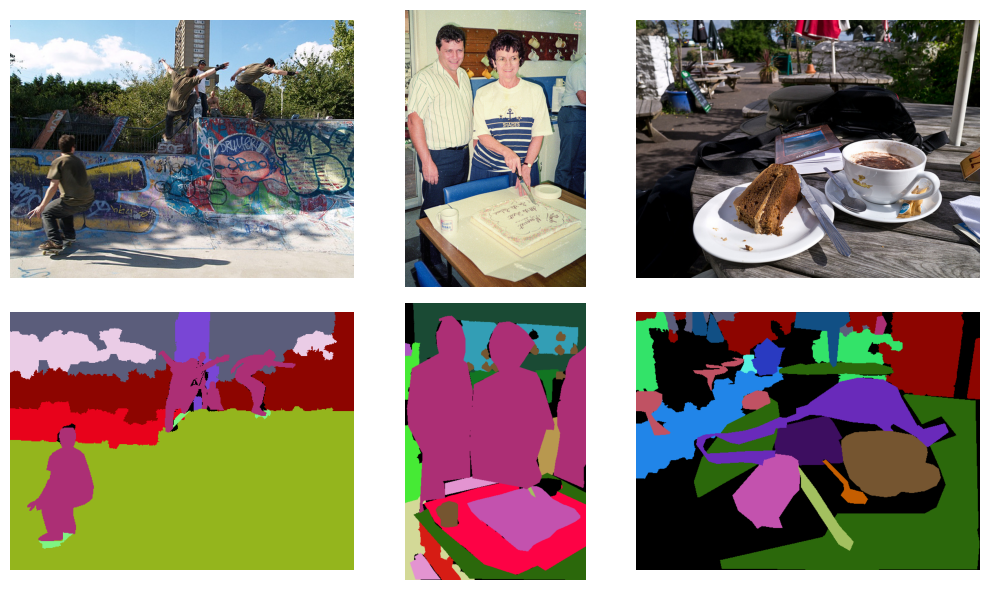

most frequent classes (first 200 train images): ['person', 'sky-other', 'grass', 'building-other', 'clouds', 'tree']


In [5]:
# quick sanity check of the converted labels
import matplotlib.pyplot as plt
rng = np.random.RandomState(0)
PALETTE = rng.randint(0, 255, (256, 3)).astype(np.uint8); PALETTE[IGNORE] = 0
fig, ax = plt.subplots(2, 3, figsize=(10, 6))
for j, n in enumerate(TRAIN_NAMES[:3]):
    ax[0, j].imshow(Image.open(ROOT / "images" / f"{n}.jpg")); ax[0, j].axis("off")
    ax[1, j].imshow(PALETTE[np.array(Image.open(ROOT / "labels_png" / f"{n}.png"))]); ax[1, j].axis("off")
plt.tight_layout(); plt.show()
cnt = np.zeros(256, np.int64)
for n in TRAIN_NAMES[:200]:
    cnt += np.bincount(np.array(Image.open(ROOT / "labels_png" / f"{n}.png")).ravel(), minlength=256)
print("most frequent classes (first 200 train images):", [CLASS_NAMES[i] for i in np.argsort(-cnt[:171])[:6]])

## 4. Augmentation and data loading

| Level | What it does | Role |
|---|---|---|
| `none` | resize short side to S, **center crop** SxS, no randomness | cannot batch variable-size images otherwise (DEV-13) |
| `standard` | MMSeg-style: random rescale 0.5-2.0 of the short side, random crop with `cat_max_ratio=0.75`, horizontal flip, photometric distortion | stands in for the unstated benchmark pipeline (DEV-08) |
| `strong` | `standard` with wider scale (0.35-2.5) and stronger photometric ranges, plus grayscale, blur, noise, random affine (rotation +-15 deg, shear +-5 deg), cutout (labels of erased areas become ignore), and batch-level CutMix | my own definition of "strong" |

The paper's actual augmentation, OASIS GAN synthesis, is **not** reproduced here (DEV-09). Evaluation always resizes the short side to S, runs whole-image inference, and scores at the original label resolution.

In [6]:
MEAN = torch.tensor([123.675, 116.28, 103.53]).view(3, 1, 1)
STD = torch.tensor([58.395, 57.12, 57.375]).view(3, 1, 1)

def _resize_short(img, mask, short):
    _, h, w = img.shape
    s = short / min(h, w)
    nh, nw = max(1, int(round(h * s))), max(1, int(round(w * s)))
    img = F.interpolate(img[None], size=(nh, nw), mode="bilinear", align_corners=False)[0]
    if mask is not None:
        mask = F.interpolate(mask[None, None].float(), size=(nh, nw), mode="nearest")[0, 0].to(torch.uint8)
    return img, mask

def _random_crop(img, mask, size, cat_max_ratio=0.75, tries=10):
    _, h, w = img.shape
    ch, cw = min(size, h), min(size, w)
    for _ in range(tries):
        y = random.randint(0, h - ch); x = random.randint(0, w - cw)
        m = mask[y:y + ch, x:x + cw]
        cnt = torch.bincount(m.flatten().long(), minlength=256)[:IGNORE]
        if (cnt > 0).sum() > 1 and cnt.max().item() / cnt.sum().item() < cat_max_ratio:
            break
    return img[:, y:y + ch, x:x + cw], m

def _photometric(img, s=1.0):
    # img float32 CHW in 0..255 (MMSeg PhotoMetricDistortion; s scales the ranges)
    if random.random() < 0.5:
        img = img + random.uniform(-32 * s, 32 * s)
    img = img.clamp(0, 255)
    contrast_first = random.random() < 0.5
    def contrast(x):
        if random.random() < 0.5:
            x = (x * random.uniform(1 - 0.5 * s, 1 + 0.5 * s)).clamp(0, 255)
        return x
    if contrast_first:
        img = contrast(img)
    x = img / 255.0
    if random.random() < 0.5:
        x = TVF.adjust_saturation(x, random.uniform(1 - 0.5 * s, 1 + 0.5 * s))
    if random.random() < 0.5:
        x = TVF.adjust_hue(x, random.uniform(-0.1 * s, 0.1 * s))
    img = x.clamp(0, 1) * 255.0
    if not contrast_first:
        img = contrast(img)
    return img

def _finalize(img, mask, S):
    img = (img - MEAN) / STD
    mask = mask.long()
    ph, pw = max(S - img.shape[1], 0), max(S - img.shape[2], 0)
    if ph or pw:
        img = F.pad(img, (0, pw, 0, ph), value=0.0)
        mask = F.pad(mask, (0, pw, 0, ph), value=IGNORE)
    return img, mask

def _random_affine(img, mask, max_rot=15, max_shear=5, scale=(0.9, 1.1)):
    # img: normalized float CHW, mask: long HW, both square. Out-of-image areas become 0 / ignore.
    _, H, W = img.shape
    ang = math.radians(random.uniform(-max_rot, max_rot))
    shx = math.tan(math.radians(random.uniform(-max_shear, max_shear)))
    sc = random.uniform(*scale)
    c, s = math.cos(ang), math.sin(ang)
    theta = torch.tensor([[c / sc, (c * shx - s) / sc, 0.0], [s / sc, (s * shx + c) / sc, 0.0]], dtype=torch.float32)[None]
    grid = F.affine_grid(theta, size=(1, 1, H, W), align_corners=False)
    img = F.grid_sample(img[None], grid, mode="bilinear", padding_mode="zeros", align_corners=False)[0]
    m = F.grid_sample(mask[None, None].float(), grid, mode="nearest", padding_mode="zeros", align_corners=False)[0, 0]
    valid = F.grid_sample(torch.ones(1, 1, H, W), grid, mode="nearest", padding_mode="zeros", align_corners=False)[0, 0] > 0.5
    m = m.long(); m[~valid] = IGNORE
    return img, m

def _cutout(img, mask, n_max=6, frac=(0.05, 0.25)):
    _, H, W = img.shape
    for _ in range(random.randint(1, n_max)):
        h = int(H * random.uniform(*frac)); w = int(W * random.uniform(*frac))
        if h < 1 or w < 1:
            continue
        y = random.randint(0, H - h); x = random.randint(0, W - w)
        img[:, y:y + h, x:x + w] = 0.0
        mask[y:y + h, x:x + w] = IGNORE
    return img, mask

def apply_train_aug(img_u8, mask_u8, S, aug):
    img = img_u8.float()
    if aug == "none":
        img, mask = _resize_short(img, mask_u8, S)
        _, h, w = img.shape
        y, x = (h - S) // 2, (w - S) // 2
        img, mask = img[:, y:y + S, x:x + S], mask[y:y + S, x:x + S]
        return _finalize(img, mask, S)
    strong = aug == "strong"
    lo, hi = (0.35, 2.5) if strong else (0.5, 2.0)
    img, mask = _resize_short(img, mask_u8, max(8, int(round(S * random.uniform(lo, hi)))))
    img, mask = _random_crop(img, mask, S)
    if random.random() < 0.5:
        img, mask = img.flip(-1), mask.flip(-1)
    img = _photometric(img, 1.5 if strong else 1.0)
    if strong:
        if random.random() < 0.1:
            img = img.mean(0, keepdim=True).expand_as(img).contiguous()
        if random.random() < 0.3:
            k = random.choice([3, 5, 7])
            img = TVF.gaussian_blur(img, kernel_size=[k, k], sigma=[random.uniform(0.1, 2.0)] * 2)
        if random.random() < 0.3:
            img = (img + torch.randn_like(img) * random.uniform(0, 10)).clamp(0, 255)
    img, mask = _finalize(img, mask, S)
    if strong:
        if random.random() < 0.5:
            img, mask = _random_affine(img, mask)
        if random.random() < 0.5:
            img, mask = _cutout(img, mask)
    return img, mask

def cutmix_batch(x, y, p=0.5, area=(0.1, 0.4)):
    if random.random() > p or x.size(0) < 2:
        return x, y
    B, _, H, W = x.shape
    perm = torch.randperm(B, device=x.device)
    a = random.uniform(*area)
    h, w = max(1, int(H * math.sqrt(a))), max(1, int(W * math.sqrt(a)))
    y0, x0 = random.randint(0, H - h), random.randint(0, W - w)
    x, y = x.clone(), y.clone()
    x[:, :, y0:y0 + h, x0:x0 + w] = x[perm][:, :, y0:y0 + h, x0:x0 + w]
    y[:, y0:y0 + h, x0:x0 + w] = y[perm][:, y0:y0 + h, x0:x0 + w]
    return x, y

class SegDataset(Dataset):
    def __init__(self, root, names, kind, size, aug="standard"):
        self.root, self.names, self.kind, self.size, self.aug = Path(root), names, kind, size, aug
    def __len__(self):
        return len(self.names)
    def __getitem__(self, i):
        n = self.names[i]
        img = torch.from_numpy(np.array(Image.open(self.root / "images" / f"{n}.jpg").convert("RGB"))).permute(2, 0, 1).contiguous()
        lab = torch.from_numpy(np.array(Image.open(self.root / "labels_png" / f"{n}.png")))
        if self.kind == "train":
            return apply_train_aug(img, lab, self.size, self.aug)
        x, _ = _resize_short(img.float(), None, self.size)
        return (x - MEAN) / STD, lab.long()

def make_loader(names, kind, size, aug, bs):
    ds = SegDataset(ROOT, names, kind, size, aug)
    nw = CFG["workers"]
    if kind == "train":
        return DataLoader(ds, batch_size=bs, shuffle=True, num_workers=nw, drop_last=True,
                          pin_memory=DEVICE.type == "cuda", persistent_workers=nw > 0)
    return DataLoader(ds, batch_size=1, shuffle=False, num_workers=min(nw, 2), pin_memory=DEVICE.type == "cuda")

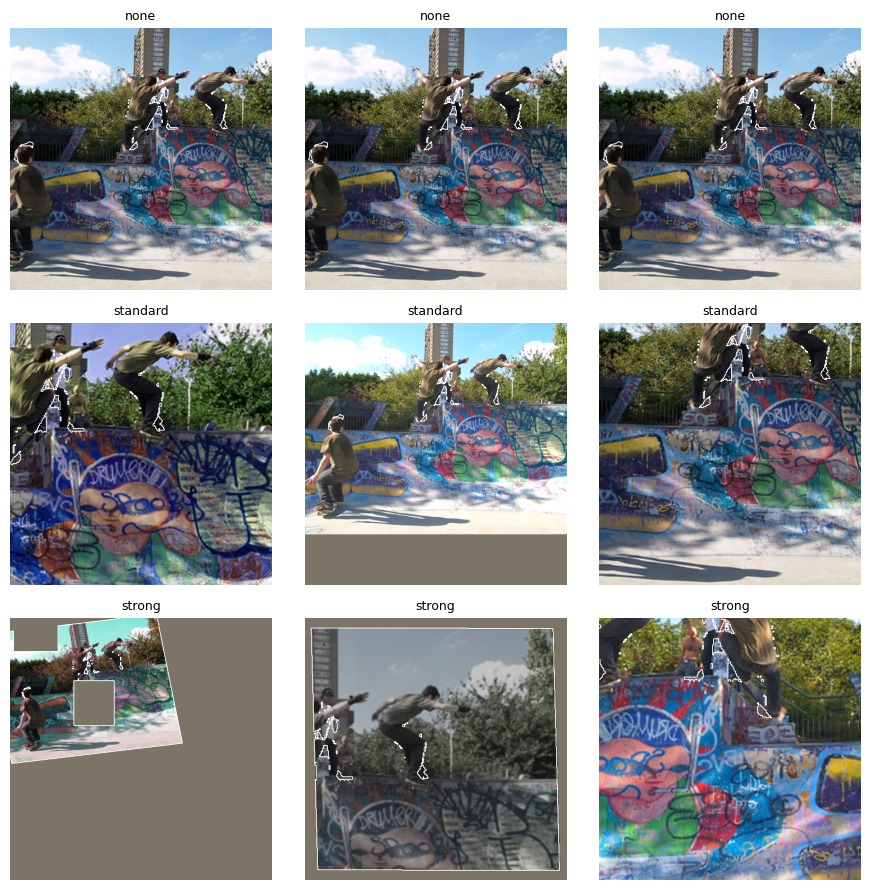

In [7]:
# optional: class-balancing weights from the paper (Eq. 6), w = median(z) / z, clipped (DEV-10)
def compute_class_weights(names, clip=(0.1, 10.0)):
    f = WORK_DIR / "class_weights.json"
    if f.exists():
        return torch.tensor(json.loads(f.read_text()), dtype=torch.float32)
    cnt = np.zeros(256, np.int64)
    for n in tqdm(names, desc="class pixel counts"):
        cnt += np.bincount(np.array(Image.open(ROOT / "labels_png" / f"{n}.png")).ravel(), minlength=256)
    z = cnt[:NUM_CLASSES] / max(cnt[:NUM_CLASSES].sum(), 1)
    zz = np.where(z > 0, z, np.nan)
    w = np.clip(np.nanmedian(zz) / zz, *clip)
    w = np.nan_to_num(w, nan=1.0)
    f.write_text(json.dumps(w.tolist()))
    return torch.tensor(w, dtype=torch.float32)

# visual check of the three augmentation levels on one training image
fig, ax = plt.subplots(3, 3, figsize=(9, 9))
for r, a in enumerate(["none", "standard", "strong"]):
    ds = SegDataset(ROOT, TRAIN_NAMES, "train", RES_LIST[0], a)
    for c in range(3):
        x, y = ds[0]
        ax[r, c].imshow((x * STD + MEAN).clamp(0, 255).permute(1, 2, 0).byte().numpy())
        ax[r, c].contour((y != IGNORE).numpy(), levels=[0.5], colors="w", linewidths=0.6)
        ax[r, c].set_title(a, fontsize=9); ax[r, c].axis("off")
plt.tight_layout(); plt.show()

## 5. Models

| Name | Description |
|---|---|
| `dlv3` | DeepLabV3: timm CNN encoder (dilated), ASPP + 3x3 bottleneck, classifier |
| `dlv3p` | DeepLabV3+: ASPP with depthwise-separable atrous branches, decoder that fuses a 48-channel stride-4 skip, two separable 3x3 convs. This is the paper's CNN. |
| `segformer` | Hugging Face SegFormer (MiT encoder + all-MLP head), ImageNet-1k encoder from `nvidia/mit-*`. This is the paper's ViT. |
| `hyb_gated` / `hyb_concat` | **My fused hybrid.** A CNN branch (ResNet/MobileNet + ASPP) and a MiT branch run in parallel on the same image. Their stride-16 features are fused by a learned gate (or concatenation). A DeepLabV3+-style decoder then refines at stride 4 using low-level features from both encoders. |
| `LateFusion` | Decision-level hybrids from two trained models: `rule` (stuff classes from DeepLabV3+, thing classes from SegFormer, the paper's stated intuition), `val` (per-class choice by validation IoU), `avg` (probability average) |

Encoders can be frozen (`freeze_encoder`); frozen encoders also keep BatchNorm in eval mode.

In [8]:
ENC_TIMM = {"resnet18": "resnet18", "resnet101": "resnet101", "mobilenetv3": "mobilenetv3_large_100"}
MIT = {"mit-b0": "nvidia/mit-b0", "mit-b1": "nvidia/mit-b1", "mit-b2": "nvidia/mit-b2", "mit-b5": "nvidia/mit-b5"}

def conv_bn_relu(i, o, k=1, d=1):
    return nn.Sequential(nn.Conv2d(i, o, k, padding=d * (k // 2), dilation=d, bias=False),
                         nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class SepConv(nn.Sequential):
    def __init__(self, i, o, k=3, d=1):
        super().__init__(
            nn.Conv2d(i, i, k, padding=d * (k // 2), dilation=d, groups=i, bias=False), nn.BatchNorm2d(i), nn.ReLU(inplace=True),
            nn.Conv2d(i, o, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class ASPP(nn.Module):
    def __init__(self, in_ch, ch, rates, sep=True):
        super().__init__()
        self.pool = nn.Sequential(nn.AdaptiveAvgPool2d(1), conv_bn_relu(in_ch, ch, 1))
        self.b0 = conv_bn_relu(in_ch, ch, 1)
        self.branches = nn.ModuleList([SepConv(in_ch, ch, 3, r) if sep else conv_bn_relu(in_ch, ch, 3, r) for r in rates])
        self.out_ch = ch * (2 + len(rates))
    def forward(self, x):
        p = F.interpolate(self.pool(x), size=x.shape[-2:], mode="bilinear", align_corners=False)
        return torch.cat([p, self.b0(x)] + [b(x) for b in self.branches], 1)

class SegModel(nn.Module):
    """Base class: encoder freezing (keeps frozen BN in eval) and encoder/head parameter split."""
    _frozen = ()
    def encoder_modules(self):
        raise NotImplementedError
    def freeze_encoder(self):
        mods = self.encoder_modules()
        for m in mods:
            for p in m.parameters():
                p.requires_grad_(False)
            m.eval()
        self._frozen = list(mods)
        return self
    def train(self, mode=True):
        super().train(mode)
        for m in self._frozen:
            m.eval()
        return self
    def split_params(self):
        enc_ids = {id(p) for m in self.encoder_modules() for p in m.parameters()}
        enc = [p for p in self.parameters() if id(p) in enc_ids and p.requires_grad]
        head = [p for p in self.parameters() if id(p) not in enc_ids and p.requires_grad]
        return enc, head

class TimmEncoder(nn.Module):
    def __init__(self, name, pretrained, output_stride):
        super().__init__()
        self.net = timm.create_model(name, pretrained=pretrained, features_only=True, output_stride=output_stride)
        self.channels = list(self.net.feature_info.channels())
        self.reductions = list(self.net.feature_info.reduction())
    def forward(self, x):
        return self.net(x)

class DeepLab(SegModel):
    def __init__(self, encoder="resnet18", plus=True, num_classes=NUM_CLASSES, pretrained=True,
                 output_stride=16, channels=256, aux=False, dropout=0.1):
        super().__init__()
        self.plus, self.aux = plus, aux
        self.encoder = TimmEncoder(ENC_TIMM[encoder], pretrained, output_stride)
        ch, red = self.encoder.channels, self.encoder.reductions
        rates = (6, 12, 18) if output_stride == 16 else (12, 24, 36)
        self.aspp = ASPP(ch[-1], channels, rates, sep=plus)
        if plus:
            self.bottleneck = SepConv(self.aspp.out_ch, channels, 3)
            self.low_idx = red.index(4)
            self.low_proj = conv_bn_relu(ch[self.low_idx], 48, 1)
            self.decoder = nn.Sequential(SepConv(channels + 48, channels, 3), SepConv(channels, channels, 3))
        else:
            self.bottleneck = conv_bn_relu(self.aspp.out_ch, channels, 3)
        self.cls = nn.Sequential(nn.Dropout2d(dropout), nn.Conv2d(channels, num_classes, 1))
        if aux:
            self.aux_head = nn.Sequential(conv_bn_relu(ch[-2], 256, 3), nn.Dropout2d(0.1), nn.Conv2d(256, num_classes, 1))
    def encoder_modules(self):
        return [self.encoder]
    def forward(self, x):
        H, W = x.shape[-2:]
        feats = self.encoder(x)
        y = self.bottleneck(self.aspp(feats[-1]))
        if self.plus:
            low = self.low_proj(feats[self.low_idx])
            y = F.interpolate(y, size=low.shape[-2:], mode="bilinear", align_corners=False)
            y = self.decoder(torch.cat([y, low], 1))
        logits = F.interpolate(self.cls(y), size=(H, W), mode="bilinear", align_corners=False)
        if self.training and self.aux:
            return logits, F.interpolate(self.aux_head(feats[-2]), size=(H, W), mode="bilinear", align_corners=False)
        return logits

class SegFormerNet(SegModel):
    def __init__(self, variant="mit-b0", num_classes=NUM_CLASSES, pretrained=True):
        super().__init__()
        name = MIT[variant]
        if pretrained:
            self.net = SegformerForSemanticSegmentation.from_pretrained(name, num_labels=num_classes, ignore_mismatched_sizes=True)
        else:
            self.net = SegformerForSemanticSegmentation(SegformerConfig.from_pretrained(name, num_labels=num_classes))
    def encoder_modules(self):
        return [self.net.segformer]
    def forward(self, x):
        out = self.net(pixel_values=x).logits
        return F.interpolate(out, size=x.shape[-2:], mode="bilinear", align_corners=False)

class HybridFusion(SegModel):
    """Fused DeepLabV3+/SegFormer hybrid (my extension; not in the paper).
    CNN branch: timm encoder (stride 16) + separable ASPP  -> local texture + multi-scale context.
    MiT branch: 4 hierarchical stages -> all-MLP style projection to stride 16 -> global context.
    Fusion at stride 16: learned gate g*A + (1-g)*V, or concat+1x1.
    Decoder: DeepLabV3+-style at stride 4 using low-level features from BOTH encoders."""
    def __init__(self, cnn="resnet18", mit="mit-b0", num_classes=NUM_CLASSES, pretrained=True,
                 channels=256, fusion="gated", dropout=0.1):
        super().__init__()
        self.fusion = fusion
        self.cnn = TimmEncoder(ENC_TIMM[cnn], pretrained, 16)
        name = MIT[mit]
        self.mit = SegformerModel.from_pretrained(name) if pretrained else SegformerModel(SegformerConfig.from_pretrained(name))
        mc = list(self.mit.config.hidden_sizes)
        cc, red = self.cnn.channels, self.cnn.reductions
        self.low_idx = red.index(4)
        self.aspp = ASPP(cc[-1], channels, (6, 12, 18), sep=True)
        self.aspp_proj = SepConv(self.aspp.out_ch, channels, 3)
        self.mit_proj = nn.ModuleList([conv_bn_relu(c, channels, 1) for c in mc])
        self.mit_fuse = conv_bn_relu(channels * len(mc), channels, 1)
        if fusion == "gated":
            self.gate = nn.Sequential(nn.Conv2d(2 * channels, channels, 1), nn.Sigmoid())
        elif fusion == "concat":
            self.fuse = conv_bn_relu(2 * channels, channels, 1)
        else:
            raise ValueError(fusion)
        self.low_cnn = conv_bn_relu(cc[self.low_idx], 48, 1)
        self.low_mit = conv_bn_relu(mc[0], 48, 1)
        self.decoder = nn.Sequential(SepConv(channels + 96, channels, 3), SepConv(channels, channels, 3))
        self.cls = nn.Sequential(nn.Dropout2d(dropout), nn.Conv2d(channels, num_classes, 1))
    def encoder_modules(self):
        return [self.cnn, self.mit]
    def forward(self, x):
        H, W = x.shape[-2:]
        cf = self.cnn(x)
        a = self.aspp_proj(self.aspp(cf[-1]))
        mf = self.mit(pixel_values=x, output_hidden_states=True).hidden_states
        v = torch.cat([F.interpolate(p(f), size=a.shape[-2:], mode="bilinear", align_corners=False)
                       for p, f in zip(self.mit_proj, mf)], 1)
        v = self.mit_fuse(v)
        if self.fusion == "gated":
            g = self.gate(torch.cat([a, v], 1))
            z = g * a + (1 - g) * v
        else:
            z = self.fuse(torch.cat([a, v], 1))
        low_c = self.low_cnn(cf[self.low_idx])
        low_m = F.interpolate(self.low_mit(mf[0]), size=low_c.shape[-2:], mode="bilinear", align_corners=False)
        z = F.interpolate(z, size=low_c.shape[-2:], mode="bilinear", align_corners=False)
        y = self.decoder(torch.cat([z, low_c, low_m], 1))
        return F.interpolate(self.cls(y), size=(H, W), mode="bilinear", align_corners=False)

class LateFusion(nn.Module):
    """Decision-level hybrid of two trained models. w[c] = weight of model A's probability for class c."""
    def __init__(self, a, b, w):
        super().__init__()
        self.a, self.b = a, b
        self.register_buffer("w", torch.as_tensor(w, dtype=torch.float32).view(1, -1, 1, 1))
    def forward(self, x):
        pa = F.softmax(self.a(x).float(), 1)
        pb = F.softmax(self.b(x).float(), 1)
        return self.w * pa + (1 - self.w) * pb

@dataclass
class RunSpec:
    arch: str                    # dlv3 | dlv3p | segformer | hyb_gated | hyb_concat
    encoder: str = "resnet18"    # CNN key for dlv3*/ MiT key for segformer and hyb_*
    cnn: str = "resnet18"        # CNN key used only by hyb_*
    res: int = 0                 # 0 -> BASE_RES
    aug: str = "standard"
    freeze: bool = False
    optim: str = "auto"          # auto: SGD for dlv3*, AdamW otherwise
    seed: int = 0
    iters: int = 0               # 0 -> CFG
    bs: int = 0                  # 0 -> CFG
    output_stride: int = 16
    channels: int = 256
    aux: bool = False
    class_balance: bool = False
    tag: str = ""
    def __post_init__(self):
        if self.res == 0:
            self.res = BASE_RES
    @property
    def name(self):
        p = [self.arch] + ([self.cnn, self.encoder] if self.arch.startswith("hyb") else [self.encoder])
        p += [f"r{self.res}", self.aug, "frozen" if self.freeze else "ft"]
        if self.optim != "auto": p.append(self.optim)
        if self.class_balance: p.append("cb")
        if self.output_stride != 16: p.append(f"os{self.output_stride}")
        if self.aux: p.append("aux")
        if self.tag: p.append(self.tag)
        p.append(f"s{self.seed}")
        return "-".join(p)

def build_model(spec, pretrained=True):
    if spec.arch in ("dlv3", "dlv3p"):
        m = DeepLab(spec.encoder, plus=spec.arch == "dlv3p", pretrained=pretrained,
                    output_stride=spec.output_stride, channels=spec.channels, aux=spec.aux)
    elif spec.arch == "segformer":
        m = SegFormerNet(spec.encoder, pretrained=pretrained)
    elif spec.arch.startswith("hyb_"):
        m = HybridFusion(spec.cnn, spec.encoder, pretrained=pretrained, channels=spec.channels, fusion=spec.arch.split("_")[1])
    else:
        raise ValueError(spec.arch)
    if spec.freeze:
        m.freeze_encoder()
    return m

## 6. Training, evaluation and profiling

**Optimisers (paper Table 6 + MMSeg defaults, DEV-07):**
* DeepLab family: SGD, lr 1e-2, momentum 0.9, weight decay 5e-4, poly decay (power 0.9, min lr 1e-4). LR and weight decay are from the paper; the rest is MMSeg default.
* SegFormer and hybrids: AdamW, lr 6e-5 (head x10), weight decay 0.01 (none on norm/bias), poly power 1.0 with linear warmup. LR and weight decay are from the paper; the rest follows the SegFormer/MMSeg recipe.

**Metrics:** mIoU (headline, paper Eq. 5 averaged), mean class accuracy, pixel accuracy, frequency-weighted IoU, mean Dice/F1, things-mIoU, stuff-mIoU and per-class IoU, all from one confusion matrix accumulated over the full test set.
**Efficiency:** parameters, GFLOPs (conv/matmul only, `FlopCounterMode`, 2 FLOPs per MAC), batch-1 latency/FPS after warmup, peak GPU memory for inference and for training (includes weights), training throughput.

In [9]:
class NullScaler:
    def scale(self, x): return x
    def step(self, o): o.step()
    def update(self): pass

def make_scaler():
    if not (USE_AMP and AMP_DTYPE == torch.float16):
        return NullScaler()
    try:
        return torch.amp.GradScaler("cuda")
    except Exception:
        return torch.cuda.amp.GradScaler()

def make_optimizer(model, spec):
    name = spec.optim if spec.optim != "auto" else ("sgd" if spec.arch in ("dlv3", "dlv3p") else "adamw")
    enc, head = model.split_params()
    if name == "sgd":
        opt = torch.optim.SGD(enc + head, lr=0.01, momentum=0.9, weight_decay=5e-4)
        return opt, dict(power=0.9, min_ratio=1e-4 / 0.01, warmup=0)
    groups = []
    for params, lr in ((enc, 6e-5), (head, 6e-4)):
        dec = [p for p in params if p.ndim > 1]; nodec = [p for p in params if p.ndim <= 1]
        if dec: groups.append(dict(params=dec, lr=lr, weight_decay=0.01))
        if nodec: groups.append(dict(params=nodec, lr=lr, weight_decay=0.0))
    return torch.optim.AdamW(groups, betas=(0.9, 0.999)), dict(power=1.0, min_ratio=0.0, warmup=CFG["warmup"])

def lr_lambda(total, warmup, power, min_ratio, warmup_ratio=1e-6):
    def f(it):
        if it < warmup:
            return warmup_ratio + (1 - warmup_ratio) * it / max(1, warmup)
        prog = min(1.0, (it - warmup) / max(1, total - warmup))
        return (1 - prog) ** power * (1 - min_ratio) + min_ratio
    return f

def forward_padded(model, x, mult=32):
    h, w = x.shape[-2:]
    ph, pw = (-h) % mult, (-w) % mult
    if ph or pw:
        x = F.pad(x, (0, pw, 0, ph))
    out = model(x)
    return out[..., :h, :w]

def metrics_from_conf(conf):
    c = conf.double().cpu()
    tp, gt, pr = c.diag(), c.sum(1), c.sum(0)
    union = gt + pr - tp
    nan = torch.tensor(float("nan"), dtype=torch.double)
    iou = torch.where(union > 0, tp / union.clamp(min=1), nan)
    acc = torch.where(gt > 0, tp / gt.clamp(min=1), nan)
    dice = torch.where((gt + pr) > 0, 2 * tp / (gt + pr).clamp(min=1), nan)
    freq = gt / gt.sum().clamp(min=1)
    stuff = torch.as_tensor(IS_STUFF)
    r = lambda t: float(t) * 100
    return dict(mIoU=r(iou.nanmean()), mAcc=r(acc.nanmean()), aAcc=r(tp.sum() / c.sum().clamp(min=1)),
                FWIoU=r(torch.nansum(freq * iou)), mDice=r(dice.nanmean()),
                mIoU_things=r(iou[~stuff].nanmean()), mIoU_stuff=r(iou[stuff].nanmean()),
                per_class_iou=[None if torch.isnan(v) else float(v) * 100 for v in iou])

@torch.no_grad()
def evaluate(model, loader, max_images=None):
    model.eval()
    conf = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=DEVICE)
    for i, (x, y) in enumerate(loader):
        if max_images and i >= max_images:
            break
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            logits = forward_padded(model, x)
        pred = F.interpolate(logits.float(), size=y.shape[-2:], mode="bilinear", align_corners=False).argmax(1)
        v = y != IGNORE
        conf += torch.bincount(y[v] * NUM_CLASSES + pred[v], minlength=NUM_CLASSES ** 2).view(NUM_CLASSES, NUM_CLASSES)
    return metrics_from_conf(conf)

def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

@torch.no_grad()
def profile_model(model, size):
    from torch.utils.flop_counter import FlopCounterMode
    model.eval()
    x = torch.randn(1, 3, size, size, device=DEVICE)
    out = dict(params_M=sum(p.numel() for p in model.parameters()) / 1e6,
               trainable_params_M=sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6)
    try:
        with FlopCounterMode(display=False) as fc:
            model(x)
        out["GFLOPs"] = fc.get_total_flops() / 1e9
    except Exception as e:
        out["GFLOPs"] = None; print("FLOP count failed:", e)
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
        for _ in range(CFG["bench_warmup"]):
            model(x)
        sync(); t0 = time.perf_counter()
        for _ in range(CFG["bench_iters"]):
            model(x)
        sync(); dt = (time.perf_counter() - t0) / CFG["bench_iters"]
    out.update(latency_ms=dt * 1000, fps=1.0 / dt,
               mem_infer_MB=torch.cuda.max_memory_allocated() / 2 ** 20 if DEVICE.type == "cuda" else None)
    return out

def infinite(loader):
    while True:
        for b in loader:
            yield b

def train_model(model, spec):
    iters, bs = spec.iters or CFG["iters"], spec.bs or CFG["bs"]
    loader = make_loader(TRAIN_NAMES, "train", spec.res, spec.aug, bs)
    opt, sch_cfg = make_optimizer(model, spec)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda(iters, sch_cfg["warmup"], sch_cfg["power"], sch_cfg["min_ratio"]))
    scaler = make_scaler()
    cw = compute_class_weights(TRAIN_NAMES).to(DEVICE) if spec.class_balance else None
    ce = lambda lg, y: F.cross_entropy(lg, y, weight=cw, ignore_index=IGNORE)
    val_loader = make_loader(VAL_NAMES, "eval", spec.res, "none", 1) if VAL_NAMES else None   # no validation set in the final run
    # resume support: a checkpoint (model + optimiser + schedule) is written every ckpt_every iterations
    ck_every = CFG.get("ckpt_every", 0)
    ck_path = CKPT_DIR / f"{spec.name}.resume.pt"
    start, t_prev, losses0 = 0, 0.0, []
    if ck_every and ck_path.exists():
        ck = torch.load(ck_path, map_location=DEVICE, weights_only=False)
        if ck.get("iters") == iters and ck.get("bs") == bs:      # only resume a run with the same schedule
            model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
            if hasattr(scaler, "state_dict") and ck.get("scaler"):
                scaler.load_state_dict(ck["scaler"])
            start, t_prev, losses0 = ck["it"], ck["elapsed"], ck["losses"]
            print(f"resuming {spec.name} from iteration {start}/{iters}")
        else:
            print("ignoring a resume file from a different schedule; starting from iteration 0")
        del ck
    model.train()
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    sync(); t0 = time.time()
    it_loader, losses, log = infinite(loader), list(losses0), []
    pbar = tqdm(range(start, iters), desc=spec.name, leave=False, initial=start, total=iters)
    for it in pbar:
        x, y = next(it_loader)
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        if spec.aug == "strong":
            x, y = cutmix_batch(x, y)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            out = model(x)
            loss = ce(out[0], y) + 0.4 * ce(out[1], y) if isinstance(out, tuple) else ce(out, y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update(); sched.step()
        losses.append(loss.item())
        if it % 50 == 0:
            pbar.set_postfix(loss=float(np.mean(losses[-50:])))
        if CFG["eval_every"] and (it + 1) % CFG["eval_every"] == 0 and it + 1 < iters:
            m = evaluate(model, val_loader, max_images=200)
            log.append(dict(iter=it + 1, val_mIoU_200=m["mIoU"])); model.train()
        if ck_every and (it + 1) % ck_every == 0 and it + 1 < iters:
            tmp = Path(str(ck_path) + ".tmp")          # write then rename, so a disconnect never leaves a half-written file
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                            scaler=scaler.state_dict() if hasattr(scaler, "state_dict") else None,
                            it=it + 1, iters=iters, bs=bs, elapsed=t_prev + (time.time() - t0), losses=losses[-100:]), tmp)
            tmp.replace(ck_path)
    sync(); dt = time.time() - t0
    return dict(train_time_s=t_prev + dt, train_img_per_s=(iters - start) * bs / dt, final_loss=float(np.mean(losses[-100:])),
                mem_train_MB=torch.cuda.max_memory_allocated() / 2 ** 20 if DEVICE.type == "cuda" else None,
                iters=iters, bs=bs, val_log=log)

def result_path(name):
    return RES_DIR / f"{name}.json"

def load_result(name):
    return json.loads(result_path(name).read_text())

def finish(name, spec_dict, model, res, extra):
    test = evaluate(model, make_loader(TEST_NAMES, "eval", res, "none", 1))
    val = evaluate(model, make_loader(VAL_NAMES, "eval", res, "none", 1)) if VAL_NAMES else dict(mIoU=float("nan"))
    prof = profile_model(model, res)
    r = dict(name=name, spec=spec_dict, test=test, val=val, eff=prof, train=extra,
             env=dict(torch=torch.__version__, device=str(DEVICE), preset=PRESET,
                      gpu=torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu", amp=USE_AMP))
    result_path(name).write_text(json.dumps(r))
    return r

def run_experiment(spec, force=False):
    if result_path(spec.name).exists() and not force:
        return load_result(spec.name)
    seed_all(spec.seed)
    model = build_model(spec).to(DEVICE)
    extra = train_model(model, spec)
    torch.save(model.state_dict(), CKPT_DIR / f"{spec.name}.pt")
    (CKPT_DIR / f"{spec.name}.resume.pt").unlink(missing_ok=True)       # run finished: the resume file is no longer needed
    r = finish(spec.name, asdict(spec), model, spec.res, extra)
    del model; gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return r

def run_safe(spec):
    """run_experiment, but on CUDA out-of-memory retry with half the batch size and twice the iterations."""
    from dataclasses import replace as _replace
    oom = False
    try:
        return run_experiment(spec)
    except torch.cuda.OutOfMemoryError:
        oom = True
    (CKPT_DIR / f"{spec.name}.resume.pt").unlink(missing_ok=True)       # a retry changes batch size/schedule, so never resume from the old file
    gc.collect(); torch.cuda.empty_cache()          # outside the except block, so the failed run's tensors are freed
    bs = (spec.bs or CFG["bs"]) // 2
    if bs < 2:
        raise RuntimeError(f"{spec.name}: out of memory even at batch size 2")
    iters = (spec.iters or CFG["iters"]) * 2
    print(f"!! OOM for {spec.name}: retrying with bs={bs}, iters={iters}")
    return run_safe(_replace(spec, bs=bs, iters=iters))

def run_group(specs, title):
    print(f"== {title}: {len(specs)} runs")
    rows = []
    for s in specs:
        r = run_safe(s)
        rows.append(r)
        print(f"{s.name:70s} mIoU {r['test']['mIoU']:6.2f} | {r['eff']['latency_ms']:7.1f} ms | "
              f"{r['eff']['params_M']:6.1f} M params")
    return rows

In [10]:
# decision-level hybrids from two already-trained models (no extra training)
def load_trained(spec):
    m = build_model(spec, pretrained=False).to(DEVICE)
    m.load_state_dict(torch.load(CKPT_DIR / f"{spec.name}.pt", map_location=DEVICE))
    return m.eval()

def late_fusion_weights(mode, res_a, res_b):
    if mode == "avg":
        return np.full(NUM_CLASSES, 0.5)
    if mode == "rule":                                   # stuff -> DeepLab (A), things -> SegFormer (B)
        return IS_STUFF.astype(float)
    a = np.array([np.nan if v is None else v for v in res_a["val"]["per_class_iou"]], float)
    b = np.array([np.nan if v is None else v for v in res_b["val"]["per_class_iou"]], float)
    w = np.where(a > b, 1.0, 0.0)
    return np.where(np.isnan(a) | np.isnan(b) | (a == b), 0.5, w)

def run_late_fusion(spec_a, spec_b, mode, force=False):
    name = f"late-{mode}__{spec_a.name}__{spec_b.name}"
    if result_path(name).exists() and not force:
        return load_result(name)
    ra, rb = load_result(spec_a.name), load_result(spec_b.name)
    w = late_fusion_weights(mode, ra, rb)
    model = LateFusion(load_trained(spec_a), load_trained(spec_b), w).to(DEVICE).eval()
    r = finish(name, dict(arch=f"late_{mode}", a=spec_a.name, b=spec_b.name, res=spec_a.res, aug=spec_a.aug,
                          freeze=False, encoder=f"{spec_a.encoder}+{spec_b.encoder}", cnn="", optim="", tag=mode),
               model, spec_a.res, dict(note="no training; weights chosen from " + mode))
    del model; gc.collect()
    return r

## 7. Experiments (three final runs)

Run names are derived from the configuration, so re-running a cell skips finished runs (results are cached as JSON in `runs_final/results`).

| Run | Model | Recipe |
|---|---|---|
| 1 | SegFormer MiT-B1 | AdamW, learning rate 6e-5 (head x10), 1,000 warm-up iterations |
| 2 | DeepLabV3+ ResNet-101, output stride 16, auxiliary head | AdamW (same recipe as SegFormer, the setting that gave 31.16) |
| 3 | DeepLabV3 MobileNetV3 | SGD, learning rate 0.01, the paper's DeepLab recipe |

All three use 512 px images, batch size 8, 16,000 iterations, standard augmentation and mixed precision, trained on all 9,000 training images and scored once on the 1,000 test images.


In [11]:
def with_seeds(specs):
    out = []
    for s in specs:
        for sd in SEEDS:
            out.append(RunSpec(**{**asdict(s), "seed": sd}))
    return out

MN3_OPTIM = "sgd"            # the configuration that scored 25.78; set to "adamw" to try AdamW instead (untested)

# configurations (also used by the paper comparison below)
SEG_B1   = dict(arch="segformer", encoder="mit-b1")
R101_CFG = dict(arch="dlv3p", encoder="resnet101", optim="adamw", aux=True)
MN3_CFG  = dict(arch="dlv3", encoder="mobilenetv3", optim=MN3_OPTIM)
R18 = dict(arch="dlv3p", encoder="resnet18")     # only used by the optional class-balance extra

FINAL = with_seeds([RunSpec(**SEG_B1), RunSpec(**R101_CFG), RunSpec(**MN3_CFG)])
ALL = {s.name: s for s in FINAL}
print(len(ALL), "final runs | preset", PRESET, "| resolution", BASE_RES, "| iters", CFG["iters"], "| batch", CFG["bs"])
print("train / val / test images:", len(TRAIN_NAMES), "/", len(VAL_NAMES), "/", len(TEST_NAMES))
for s in FINAL:
    print("  ", s.name)


3 final runs | preset final | resolution 512 | iters 16000 | batch 8
train / val / test images: 9000 / 0 / 1000
   segformer-mit-b1-r512-standard-ft-s0
   dlv3p-resnet101-r512-standard-ft-adamw-aux-s0
   dlv3-mobilenetv3-r512-standard-ft-sgd-s0


In [12]:
# --- SegFormer cuDNN-engine workaround (run once, before run_group) ---
print("torch", torch.__version__, "| cuda", torch.version.cuda, "| cudnn", torch.backends.cudnn.version(),
      "| gpu", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu")

def _probe():
    m = SegFormerNet("mit-b0", pretrained=False).to(DEVICE).train()
    x = torch.randn(2, 3, BASE_RES, BASE_RES, device=DEVICE)
    try:
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            out = m(x)
        out.float().mean().backward()
        torch.cuda.synchronize()
        return True
    except RuntimeError as e:
        print("   probe failed:", str(e).splitlines()[0][:110])
        return False
    finally:
        del m, x
        gc.collect(); torch.cuda.empty_cache()

if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = False
    ok = _probe()
    if not ok:                                   # 1) try the other half-precision dtype
        AMP_DTYPE = torch.float16 if AMP_DTYPE == torch.bfloat16 else torch.bfloat16
        print("-> retry with", AMP_DTYPE); ok = _probe()
    if not ok:                                   # 2) full fp32 (no autocast)
        USE_AMP = False
        print("-> retry with AMP off (fp32)"); ok = _probe()
    if not ok:                                   # 3) bypass cuDNN entirely (slower, always works)
        torch.backends.cudnn.enabled = False
        print("-> retry with cuDNN disabled"); ok = _probe()
    print("probe OK" if ok else "still failing", "| AMP_DTYPE:", AMP_DTYPE, "| USE_AMP:", USE_AMP,
          "| cudnn.enabled:", torch.backends.cudnn.enabled)

torch 2.11.0+cpu | cuda None | cudnn None | gpu cpu


### Final 1: SegFormer MiT-B1

In [13]:
rows_SEG = run_group([s for s in FINAL if s.arch == "segformer"], "FINAL 1: SegFormer MiT-B1")

== FINAL 1: SegFormer MiT-B1: 1 runs
segformer-mit-b1-r512-standard-ft-s0                                   mIoU  36.67 |    12.2 ms |   13.7 M params


### Final 2: DeepLabV3+ ResNet-101

In [ ]:
rows_R101 = run_group([s for s in FINAL if s.encoder == "resnet101"], "FINAL 2: DeepLabV3+ ResNet-101")

== FINAL 2: DeepLabV3+ ResNet-101: 1 runs


model.safetensors: reconstructing file:   0%|          |  0.00B /  179MB            

model.safetensors: downloading bytes:           |  0.00B            

resuming dlv3p-resnet101-r512-standard-ft-adamw-aux-s0 from iteration 8000/16000


dlv3p-resnet101-r512-standard-ft-adamw-aux-s0:  50%|#####     | 8000/16000 [00:00<?, ?it/s]

### Final 3: DeepLabV3 MobileNetV3

In [ ]:
rows_MN3 = run_group([s for s in FINAL if s.encoder == "mobilenetv3"], "FINAL 3: DeepLabV3 MobileNetV3")

### Optional extras (off by default)
* **Paper-scale pair.** DeepLabV3+ ResNet-101 (output stride 8, 512 channels, aux head, crop 512, Table 6) vs SegFormer MiT-B5 (crop 640, Table 6). Needs a large GPU; the paper used 48 GB. The schedule is my choice because the paper gives none.
* **Class balancing** (paper Eq. 6) on the baseline.

In [ ]:
RUN_PAPER_SCALE = False
RUN_CLASS_BALANCE = False
PAPER_SCALE = [RunSpec(arch="dlv3p", encoder="resnet101", res=512, output_stride=8, channels=512, aux=True,
                       iters=CFG["iters"] * 2, bs=CFG["bs"], tag="paperscale"),
               RunSpec(arch="segformer", encoder="mit-b5", res=640, iters=CFG["iters"] * 2, bs=CFG["bs"], tag="paperscale")]
if RUN_PAPER_SCALE:
    run_group(PAPER_SCALE, "paper-scale pair (R101-D8 / MiT-B5)")
if RUN_CLASS_BALANCE:
    run_group([RunSpec(**R18, class_balance=True)], "class balancing (paper Eq. 6)")

## 8. Results, comparison with the paper, deviations, report
All cells below only read cached JSON results, so they can be re-run freely.

In [ ]:
import matplotlib.pyplot as plt
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # reference categorical order
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.axisbelow": True, "figure.dpi": 110})

CFG_COLS = ["arch", "encoder", "cnn", "res", "aug", "freeze", "optim", "class_balance", "output_stride", "aux", "tag"]
METRICS = ["mIoU", "mAcc", "aAcc", "FWIoU", "mDice", "mIoU_things", "mIoU_stuff"]
EFF = ["params_M", "trainable_params_M", "GFLOPs", "latency_ms", "fps", "mem_infer_MB"]

def collect_results():
    rows = []
    for f in sorted(RES_DIR.glob("*.json")):
        r = json.loads(f.read_text()); s = r["spec"]
        row = {"name": r["name"], **{k: s.get(k, "") for k in CFG_COLS}, "seed": s.get("seed", 0)}
        row.update({k: r["test"][k] for k in METRICS})
        row.update({"val_mIoU": r["val"]["mIoU"]})
        row.update({k: r["eff"].get(k) for k in EFF})
        row.update({"mem_train_MB": r["train"].get("mem_train_MB"), "train_min": (r["train"].get("train_time_s") or 0) / 60,
                    "train_img_s": r["train"].get("train_img_per_s")})
        rows.append(row)
    cols = ["name"] + CFG_COLS + ["seed"] + METRICS + ["val_mIoU"] + EFF + ["mem_train_MB", "train_min", "train_img_s"]
    df = pd.DataFrame(rows, columns=cols)
    num = METRICS + ["val_mIoU"] + EFF + ["mem_train_MB", "train_min", "train_img_s"]
    df[num] = df[num].apply(pd.to_numeric, errors="coerce")
    return df

def label(row):
    a = {"dlv3": "DeepLabV3", "dlv3p": "DeepLabV3+", "segformer": "SegFormer", "hyb_gated": "Hybrid-gated",
         "hyb_concat": "Hybrid-concat"}.get(row["arch"], row["arch"])
    enc = row["encoder"] if row["arch"] != "hyb_gated" and row["arch"] != "hyb_concat" else f'{row["cnn"]}+{row["encoder"]}'
    return f'{a} [{enc}]'

DF = collect_results()
def agg(df):
    num = METRICS + EFF + ["mem_train_MB", "train_min", "val_mIoU"]
    if df.empty:
        return pd.DataFrame(columns=CFG_COLS + num + ["n_seeds", "mIoU_std", "model"])
    df = df.copy()
    for c in CFG_COLS:                       # mixed bool/"" values (late-fusion rows) -> strings are not needed, keep as-is
        df[c] = df[c].astype(object)
    g = df.groupby(CFG_COLS, dropna=False, sort=False)
    out = g[num].mean().reset_index()
    out["n_seeds"] = g.size().values
    out["mIoU_std"] = g["mIoU"].std().values
    out["model"] = out.apply(label, axis=1)
    return out
AGG = agg(DF)

def show(mask, cols, title):
    d = AGG[mask]
    print(f"\n### {title}")
    if d.empty:
        print("(no runs found yet)"); return d
    d = d[["model", "res", "aug", "freeze"] + cols + ["n_seeds"]].round(2)
    display(d) if "display" in globals() else print(d.to_string(index=False))
    return d

def sel(**kw):
    m = pd.Series(True, index=AGG.index)
    for k, v in kw.items():
        m &= AGG[k] == v
    return m

KEY = ["mIoU", "mAcc", "aAcc", "mIoU_things", "mIoU_stuff", "params_M", "GFLOPs", "latency_ms", "mem_infer_MB", "mem_train_MB"]

# ---- leaderboard: new score next to the score from the first study (4,000 iterations) ----
def _optname(arch, optim):
    return optim if optim != "auto" else ("sgd" if arch in ("dlv3", "dlv3p") else "adamw")

def _key(arch, encoder, cnn, optim):
    return (arch, encoder, cnn if str(arch).startswith("hyb") else "", _optname(arch, optim))

# test mIoU of the focused study (8,000 iterations, 384 px, 8,100 training images, seed 0)
PREV = {("segformer", "mit-b1", "", "adamw"): 33.37,
        ("dlv3p", "resnet101", "", "adamw"): 31.16,
        ("dlv3", "mobilenetv3", "", "sgd"): 25.78}
GROUP_OF = {_key(s.arch, s.encoder, s.cnn, s.optim): g
            for g, lst in (("segformer", [s for s in FINAL if s.arch == "segformer"]),
                           ("deeplab-r101", [s for s in FINAL if s.encoder == "resnet101"]),
                           ("deeplab-mnv3", [s for s in FINAL if s.encoder == "mobilenetv3"])) for s in lst}
LEADER_COLS = ["group", "model", "optimizer", "mIoU", "prev_mIoU", "gain", "mIoU_things", "mIoU_stuff",
               "params_M", "GFLOPs", "latency_ms", "mem_train_MB", "train_min"]

_single = AGG[AGG.arch.isin(["dlv3", "dlv3p", "segformer", "hyb_gated", "hyb_concat"])] if not AGG.empty else AGG
LEADER = _single.copy()
if not LEADER.empty:
    keys = [_key(r.arch, r.encoder, r.cnn, r.optim) for r in LEADER.itertuples()]
    LEADER["optimizer"] = [k[3] for k in keys]
    LEADER["group"] = [GROUP_OF.get(k, "other") for k in keys]
    LEADER["prev_mIoU"] = [PREV.get(k, float("nan")) for k in keys]
    LEADER["gain"] = LEADER["mIoU"] - LEADER["prev_mIoU"]
    LEADER = LEADER.sort_values("mIoU", ascending=False)
    print("\n### Leaderboard (test mIoU, %; prev_mIoU = focused study: 8,000 iterations, 384 px, 8,100 training images)")
    d = LEADER[LEADER_COLS].round(2)
    display(d) if "display" in globals() else print(d.to_string(index=False))
else:
    print("(no runs found yet: run the experiment cells first)")



In [ ]:
if not AGG.empty and not LEADER.empty:
    from matplotlib.patches import Patch
    GCOL = {"segformer": SERIES[0], "deeplab-r101": SERIES[1], "deeplab-mnv3": SERIES[2], "other": "#888888"}
    d = LEADER.iloc[::-1].reset_index(drop=True)
    ypos = np.arange(len(d))
    fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.2))
    ax[0].barh(ypos, d["mIoU"], color=[GCOL.get(g, "#888888") for g in d["group"]], height=0.55)
    ax[0].scatter(d["prev_mIoU"], ypos, marker="|", s=320, color="black", zorder=3)
    ax[0].set_yticks(ypos); ax[0].set_yticklabels([f"{m} ({o})" for m, o in zip(d["model"], d["optimizer"])], fontsize=8)
    ax[0].set_xlabel("test mIoU (%)  |  black tick = focused study (8k iters, 384 px)")
    ax[0].set_title("Final run", fontsize=10)
    for y, v in zip(ypos, d["mIoU"]):
        ax[0].text(v + 0.2, y, f"{v:.2f}", va="center", fontsize=8)
    for g, grp in d.groupby("group"):
        ax[1].scatter(grp["latency_ms"], grp["mIoU"], s=60 + 6 * grp["params_M"], color=GCOL.get(g, "#888888"), alpha=0.9,
                      edgecolor="white", linewidth=1.5)
    for _, r in d.iterrows():
        ax[1].annotate(r["model"].replace("DeepLab", "DL").replace("SegFormer", "SF"), (r["latency_ms"], r["mIoU"]), fontsize=7,
                       xytext=(5, 4), textcoords="offset points")
    ax[1].set_xlabel("latency (ms, batch 1, 512 px)"); ax[1].set_ylabel("test mIoU (%)")
    ax[1].set_title("Accuracy vs speed (marker area ~ parameters)", fontsize=10)
    plt.tight_layout(); plt.show()


### 8.1 Comparison with the paper (COCO-Stuff10K, DeepLabv3+ vs SegFormer)
Absolute mIoU is **not directly comparable** unless you run the paper-scale pair with a comparable schedule. The paper uses R-101 and MiT-B5 and does not state the schedule. The claim-level checks (ranking, per-class wins, stuff vs thing pattern) are the meaningful comparison for the light models.

In [ ]:
PAPER = dict(
    miou=dict(deeplabv3plus=38.78, segformer=48.40),
    deeplab_wins_things=["surfboard", "sports ball", "car", "mouse"],
    deeplab_wins_stuff=["platform", "mountain", "stone", "straw", "bush", "bridge", "roof", "house", "cabinet",
                        "floor-other", "floor-wood", "carpet", "wall-panel"],
    top10_deeplab=["zebra", "person", "snow", "stop sign", "horse", "surfboard", "bus", "fire hydrant", "airplane", "tree"],
    top10_segformer=["snow", "cow", "broccoli", "parking meter", "bear", "elephant", "cat", "train", "fire hydrant", "zebra"],
)
PAPER_DL_WINS = PAPER["deeplab_wins_things"] + PAPER["deeplab_wins_stuff"]      # 17 classes -> SegFormer wins 154/171

def _iou(r):
    return np.array([np.nan if v is None else v for v in r["test"]["per_class_iou"]], float)

def paper_comparison(a_name, b_name, tag):
    ra, rb = load_result(a_name), load_result(b_name)
    ia, ib = _iou(ra), _iou(rb)
    ok = ~np.isnan(ia) & ~np.isnan(ib)
    dl_win = (ia > ib) & ok
    sf_win = (ib > ia) & ok
    th, st = ~IS_STUFF & ok, IS_STUFF & ok
    ours_dl_names = [CLASS_NAMES[i] for i in np.where(dl_win)[0]]
    top = lambda i: [CLASS_NAMES[j] for j in np.argsort(-np.nan_to_num(i, nan=-1))[:10]]
    rows = [
        ("mIoU DeepLab (%)", PAPER["miou"]["deeplabv3plus"], round(ra["test"]["mIoU"], 2), "scale/schedule dependent"),
        ("mIoU SegFormer (%)", PAPER["miou"]["segformer"], round(rb["test"]["mIoU"], 2), "scale/schedule dependent"),
        ("SegFormer - DeepLab (pts)", round(48.40 - 38.78, 2), round(rb["test"]["mIoU"] - ra["test"]["mIoU"], 2), "gap"),
        ("SegFormer mIoU > DeepLab mIoU", True, bool(rb["test"]["mIoU"] > ra["test"]["mIoU"]), "claim"),
        ("classes where SegFormer wins", "154/171 (90%, derived)", f"{sf_win.sum()}/{ok.sum()} ({100*sf_win.sum()/max(ok.sum(),1):.0f}%)", ""),
        ("thing classes won by DeepLab", "4/80 (5.0%)", f"{(dl_win & th).sum()}/{th.sum()} ({100*(dl_win & th).sum()/max(th.sum(),1):.1f}%)", ""),
        ("stuff classes won by DeepLab", "13/91 (14.3%)", f"{(dl_win & st).sum()}/{st.sum()} ({100*(dl_win & st).sum()/max(st.sum(),1):.1f}%)", ""),
        ("DeepLab wins larger share of stuff than things", True,
         bool((dl_win & st).sum() / max(st.sum(), 1) > (dl_win & th).sum() / max(th.sum(), 1)), "claim"),
        ("paper's 17 DeepLab-win classes also won by DeepLab here", "17/17", f"{sum(n in ours_dl_names for n in PAPER_DL_WINS)}/17", ""),
        ("top-10 overlap with paper Table 8 (DeepLab)", "10/10", f"{len(set(top(ia)) & set(PAPER['top10_deeplab']))}/10", ""),
        ("top-10 overlap with paper Table 8 (SegFormer)", "10/10", f"{len(set(top(ib)) & set(PAPER['top10_segformer']))}/10", ""),
    ]
    df = pd.DataFrame(rows, columns=["quantity", "paper", f"this run ({tag})", "note"])
    return df

PAIRS = {
    "final: R101 DeepLabV3+ vs MiT-B1": (RunSpec(**R101_CFG, seed=SEEDS[0]).name, RunSpec(**SEG_B1, seed=SEEDS[0]).name),
    "final: MobileNetV3 DeepLabV3 vs MiT-B1": (RunSpec(**MN3_CFG, seed=SEEDS[0]).name, RunSpec(**SEG_B1, seed=SEEDS[0]).name),
    "paper-scale: R101-D8 vs MiT-B5": (PAPER_SCALE[0].name, PAPER_SCALE[1].name),
}
PAPER_TABLES = {}
for tag, (a, b) in PAIRS.items():
    if result_path(a).exists() and result_path(b).exists():
        PAPER_TABLES[tag] = paper_comparison(a, b, tag)
        print(f"\n### {tag}")
        print(PAPER_TABLES[tag].to_string(index=False))
    else:
        print(f"\n### {tag}: runs not available yet")

In [ ]:
DEVIATIONS = [
 ("DEV-01","Scope","Outcrop datasets, OASIS, ADE20K experiments (Sec. 4.4-5)","Only COCO-Stuff10K DeepLabv3+ vs SegFormer (Sec. 4.6) is reproduced","Custom expert-annotated data not available; you asked for COCO-Stuff10K","Outcrop-specific findings are untested"),
 ("DEV-02","Framework","MMSegmentation","PyTorch + timm + Hugging Face; DeepLab heads re-implemented","No MMSeg dependency; needed for custom ablations and hybrid","Small architectural differences (e.g. ResNet-V1c deep stem vs timm ResNet, head details)"),
 ("DEV-03","Model scale","DeepLabv3+ R-101, SegFormer MiT-B5 (Table 6)","Ablations use R-18 / MobileNetV3 / MiT-B0 (+B1); R-101/MiT-B5 optional","Requested ablations need small encoders; GPU budget","Absolute mIoU far below paper-scale"),
 ("DEV-04","Schedule","Not stated","Fixed iterations and batch size from the preset","Unspecified in paper","Absolute mIoU and rankings may shift with longer training"),
 ("DEV-05","Split","Not stated","8,100 train / 900 val (held out from the 9k train list) / 1,000 official test","Need validation for monitoring and late-fusion weights","10 % less training data than the official 9k"),
 ("DEV-06","Resolution","512 (DeepLab), 640 (SegFormer)","Same S for both models in every comparison","Fair comparison and requested 256/384/512 sweep","Differs from Table 6 for SegFormer"),
 ("DEV-07","Optimiser","LR and weight decay only (Table 6)","SGD m=0.9 + poly 0.9 (DeepLab); AdamW, head lr x10, no decay on norm/bias, poly 1.0, warmup (SegFormer/hybrids), from MMSeg/SegFormer recipes","Unspecified in paper","Optimiser is confounded with architecture; A1 includes DeepLabV3+ with AdamW to measure it"),
 ("DEV-08","Standard augmentation","Not stated for benchmarks","MMSeg-style pipeline re-implemented in PyTorch (resize rule, crop, flip, photometric)","Inferred from MMSeg use","Minor pipeline differences"),
 ("DEV-09","OASIS GAN","Real + OASIS-synthesised images (outcrop only)","Not reproduced; strong augmentation is classical","Different data and GAN training cost; paper did not use OASIS on COCO-Stuff10K","Paper's headline augmentation is untested"),
 ("DEV-10","Class balancing","Eq. 6, used on outcrop data","Optional extra, weights clipped to [0.1, 10]","Median/frequency ratio is unbounded for rare classes with 171 classes","Only matters if enabled"),
 ("DEV-11","Evaluation","Not stated (IoU/mIoU)","Single-scale, whole image at short side S, confusion matrix over the full set at original resolution, nanmean over present classes","MMSeg-like convention","Could differ from the paper's protocol"),
 ("DEV-12","Precision","Not stated","Mixed precision (bf16/fp16) on CUDA","Speed/memory","Tiny numerical differences"),
 ("DEV-13","'No augmentation'","n/a","Deterministic resize + center crop","Fixed-size batches","Also removes edge content, confounding with augmentation"),
 ("DEV-14","Loss normalisation","MMSeg default","PyTorch CE mean over non-ignored pixels","Simplicity","Minor scaling difference"),
 ("DEV-15","Pretrained weights","Not named (see AMB-1)","ImageNet-1k encoders from timm / nvidia mit-*","Public availability","If the paper started from ADE20K checkpoints, results would differ"),
 ("DEV-16","'Hybrid'","Framework to use either backbone by target (Fig. 2 not inspected)","Decision-level fusion (paper-style) and a new fused two-branch network","You asked for a proper hybrid","The fused net is my design, not the paper's"),
 ("DEV-17","Speed/memory","Not reported (P-3)","Batch-1 latency, peak memory on your GPU","Requested","No paper baseline; GPU differs from the A6000"),
 ("DEV-18","Seeds","Not stated","One seed by default","Cost","Single-seed differences can be noise"),
 ("DEV-19","Class names/ids","COCO-Stuff10K","Names/ids hard-coded (171); ids mapped from COCO ids (0=unlabeled, 1-182, per dataset README); zip folder layout searched, not documented","Standard convention","Check the label sanity-plot in Section 3"),
 ("DEV-20","R101 recipe","SGD, output stride 8, 512 channels, auxiliary head, 512 px (paper scale)","AdamW, output stride 16, 256 channels, no auxiliary head, 384 px","Fits a 15 GB GPU; AdamW gave +4.1 mIoU for ResNet-18 in the first study","Not the paper's ResNet-101 recipe; the optional paper-scale cell runs that"),
 ("DEV-21","Memory fallback","n/a","On CUDA out-of-memory a run is retried with half the batch size and twice the iterations","Keeps the number of training images seen constant","Slightly different optimisation noise; the batch size used is stored in each result"),
 ("DEV-22","Selected models","Full model set","8 models chosen from the first study: the 4 best, 3 under-trained DeepLabV3+ variants, and a ResNet-101","Lower GPU budget","Augmentation, freezing and resolution ablations are not repeated here"),
]
_drop = ("DEV-04", "DEV-05", "DEV-06", "DEV-20", "DEV-22")
DEVIATIONS = [d for d in DEVIATIONS if d[0] not in _drop] + [
    ("DEV-04", "Schedule", "Not stated", "16,000 iterations, batch size 8, 1,000 warm-up iterations", "Unspecified in paper; about 14 passes over the data", "Absolute mIoU and rankings may still shift with longer training"),
    ("DEV-05", "Split", "Not stated (9,000 train / 1,000 test is the standard COCO-Stuff10K protocol)", "9,000 train / no validation set / 1,000 official test", "Fixed schedule and last checkpoint: nothing needs validation", "None for the final run; models were chosen in earlier rounds partly by test score, which can make results slightly optimistic"),
    ("DEV-06", "Resolution", "512 (DeepLab), 640 (SegFormer)", "512 for all three models", "Same size for a fair comparison within memory limits", "SegFormer is run below its paper size (640)"),
    ("DEV-20", "R101 recipe", "SGD, output stride 8, 512 channels, auxiliary head, 512 px", "AdamW, output stride 16, 256 channels, auxiliary head, 512 px", "Fits a 15 GB GPU; AdamW gave better scores in earlier rounds", "Not the paper's ResNet-101 recipe; the optional paper-scale cell runs that"),
    ("DEV-22", "Selected models", "Full model set", "3 final models: the best SegFormer, the best DeepLab and the best MobileNetV3 DeepLab from earlier rounds", "Lower GPU budget, final run", "Ablations and hybrids are not repeated; selection used earlier test scores"),
    ("DEV-23", "MobileNetV3 recipe", "n/a", "DeepLabV3 MobileNetV3 trained with SGD (the configuration from earlier rounds)", "Keeps the validated configuration", "AdamW was not tested for this model, so it may be slightly under-served"),
]
DEVIATIONS.sort(key=lambda d: d[0])
DEV_DF = pd.DataFrame(DEVIATIONS, columns=["id", "area", "paper", "this notebook", "reason", "expected impact"])
print(DEV_DF.to_string(index=False, max_colwidth=60))

In [ ]:
def df_to_md(df):
    d = df.copy()
    cols = list(d.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in d.iterrows():
        lines.append("| " + " | ".join("" if (isinstance(v, float) and np.isnan(v)) else (f"{v:.2f}" if isinstance(v, float) else str(v)) for v in r) + " |")
    return "\n".join(lines)

def write_report(path=WORK_DIR / "REPORT_results.md"):
    parts = [f"# Auto-generated results (preset `{PRESET}`)\n",
             f"Test images: {len(TEST_NAMES)}; val: {len(VAL_NAMES)}; train: {len(TRAIN_NAMES)}; seeds: {SEEDS}\n"]
    if "LEADER" in globals() and not LEADER.empty:
        parts += ["## Leaderboard\n", df_to_md(LEADER[LEADER_COLS].round(2)), "\n"]
    if not AGG.empty:
        cols = ["model", "res", "aug", "freeze"] + KEY + ["n_seeds"]
        parts += ["## All runs\n", df_to_md(AGG[cols].round(2)), "\n"]
    for tag, t in PAPER_TABLES.items():
        parts += [f"## Paper comparison: {tag}\n", df_to_md(t), "\n"]
    parts += ["## Deviations from the paper\n", df_to_md(DEV_DF), "\n"]
    Path(path).write_text("\n".join(parts))
    print("wrote", path)

write_report()